# Unidad 3 · Práctica 2 — Elegir y ajustar

Ciencia de Datos · UTN FRM · 2026

Segunda de las tres clases prácticas de la unidad. Se corre **de arriba hacia abajo**; la primera
celda de código reconstruye en un bloque todo lo que dejó la Práctica 1, así que no hace falta
tener aquel notebook abierto.

La Práctica 1 terminó con tres preguntas abiertas: el modelo más simple le ganó a los dos más
sofisticados, la clase Extremo casi no se predice, y todos los números eran los de una sola
partición. Esta clase las contesta en ese orden inverso: primero cómo se mide de verdad, después
qué se ajusta, y al final qué se hace con una clase que el modelo entiende pero no contesta.

## Hoja de ruta

| Parte | Qué pasa | Qué deja |
|---|---|---|
| **1** | Lo que el test no ve: la brecha entre entrenar y predecir | saber leer el sobreajuste en una tabla |
| **2** | Cuánto se mueve el número: validación cruzada | comparar modelos con una barra de error |
| **3** | Complejidad: la curva que dibuja la teoría | elegir la profundidad, la cantidad de árboles, la regularización |
| **4** | Tuneo: `GridSearchCV` sobre el pipeline entero | una búsqueda honesta, y el test tocado una sola vez |
| **5** | Las columnas que cada modelo necesita | qué darle a un modelo lineal y qué a un árbol, medido: perfiles, curvas, restas |
| **6** | El desbalance como decisión | por qué pasa, `class_weight`, umbrales y la curva precision-recall, y qué significa «mejor» |
| **7** | El puente al TP3 y al proyecto | qué se lleva tal cual, y qué cambia cuando el test son clubes que el modelo no vio |

## Lo que se hace hoy: elegir

La Práctica 1 entrenó modelos. Esta práctica **elige entre ellos**: qué familia, con qué
hiperparámetros, con qué regla de decisión. Eso se llama **selección de modelos**, y tiene un
problema que no es de programación sino de honestidad: para elegir hay que medir, y una medida
que se usó para elegir ya no sirve para informar.

Por eso los datos cumplen tres papeles distintos, y conviene tener los nombres claros antes de
que aparezcan en el código:

| Conjunto | Para qué | Cuántas veces se mira |
|---|---|---|
| **Entrenamiento** | ajustar los parámetros del modelo (los pesos, los cortes del árbol) | todas las que haga falta |
| **Validación** | comparar candidatos y elegir hiperparámetros | una vez por candidato |
| **Test** | informar cuánto acierta lo que se eligió | **una sola vez, al final** |

La Práctica 1 tenía sólo dos: entrenamiento y test, y usó el test para comparar cinco modelos. Eso
está bien para mirar una vez; está mal como método, porque si el test decide quién gana, el número
que informa ya está elegido a favor. Lo que falta es el conjunto del medio, y hoy aparece de la
forma en que se usa en la práctica: no como un tercer archivo guardado, sino como **pedazos del
entrenamiento que se dejan afuera por turnos** —la validación cruzada de la Parte 2—. El test
sigue siendo el mismo de la Práctica 1, y no se toca hasta la sección 4.3.

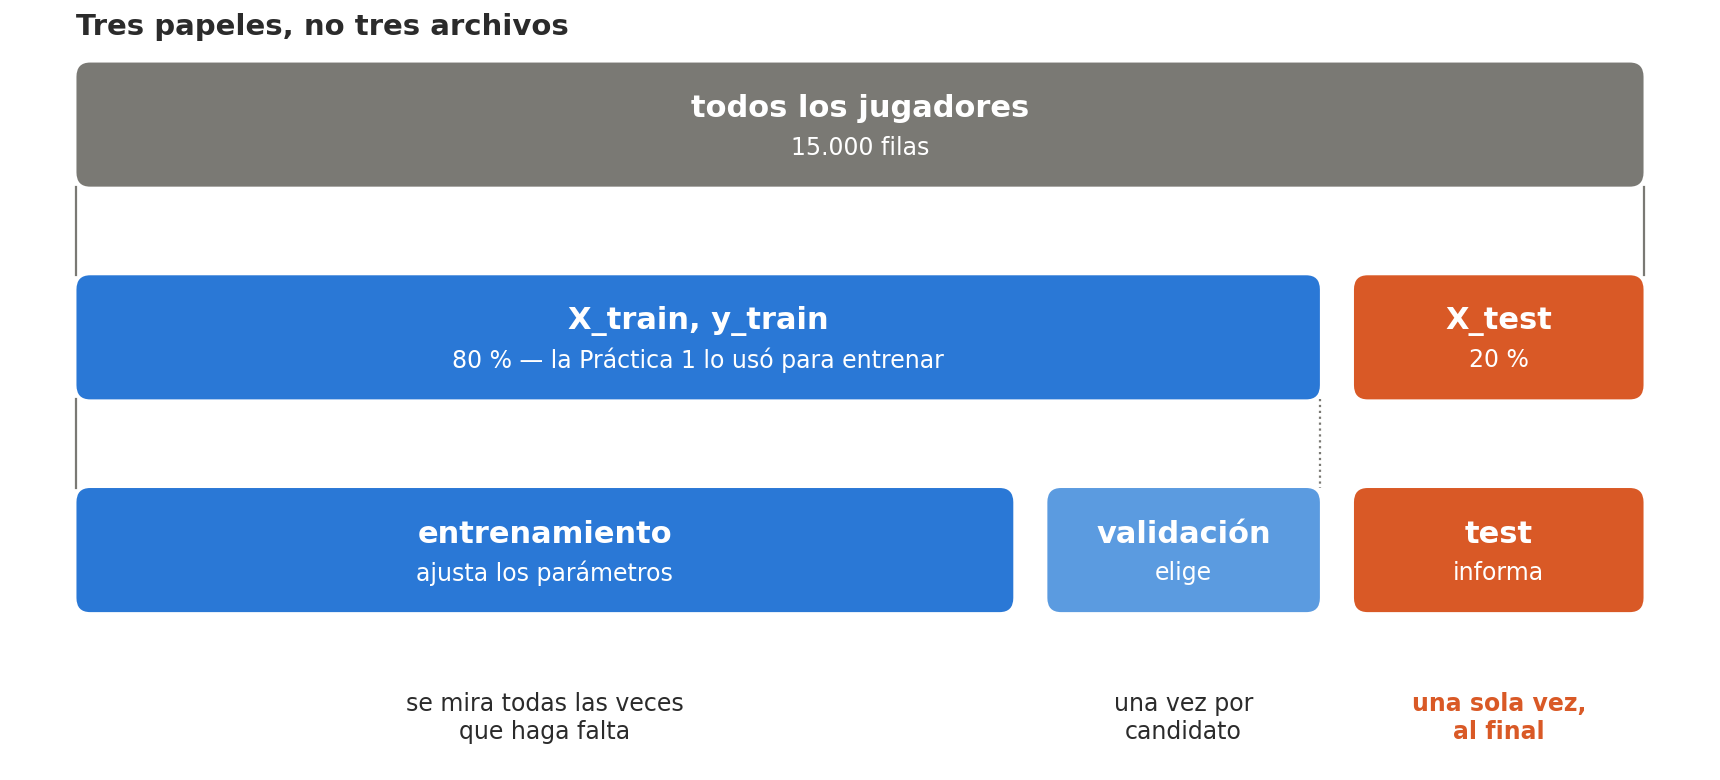

## Antes de empezar

Hace falta el mismo `fifa_canonico_2026-07-23.csv` de siempre; la celda lo baja si no está. La
segunda celda es la Práctica 1 entera comprimida: el objetivo en siete roles, las columnas que
salen por fuga, la partición con semilla, el transformador propio y `pipeline_completo`. No hay
nada nuevo ahí; si algo no se reconoce, está explicado en aquel notebook.

In [ ]:
# El dataset se baja del Drive de la cátedra la primera vez que se corre el notebook
import os

ARCHIVO  = "fifa_canonico_2026-07-23.csv"
ID_DRIVE = "1cF30_fSvxNKpK5-AKJlzUqLHZTTUf0ls"

if not os.path.exists(ARCHIVO):
    !gdown $ID_DRIVE -O $ARCHIVO

In [ ]:
# Todo lo que dejó la Práctica 1, en un bloque
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

SEMILLA = 42
df = pd.read_csv(ARCHIVO, low_memory=False)

# el objetivo: de quince posiciones a siete roles
GRUPO = {"GK": "Arquero", "CB": "Defensor central",
         "LB": "Lateral", "RB": "Lateral", "LWB": "Lateral", "RWB": "Lateral",
         "CDM": "Volante defensivo",
         "CM": "Volante", "CAM": "Volante", "LM": "Volante", "RM": "Volante",
         "LW": "Extremo", "RW": "Extremo", "ST": "Delantero", "CF": "Delantero"}
y = df["best_position"].map(GRUPO)

# las columnas que no pueden estar
FUGA = ["best_position", "player_positions", "club_position", "best_overall"]
IDS  = ["player_id", "short_name", "long_name", "player_url", "player_face_url",
        "club_team_id", "club_name", "nationality_id", "nationality_name",
        "league_id", "league_name", "league_country", "fifa_version", "fifa_update",
        "fifa_update_date", "club_joined_date", "club_loan_end_date",
        "club_jersey_number", "club_contract_valid_until_year", "player_traits"]
X = df.drop(columns=FUGA + IDS)

# la partición, con la semilla
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA)

# el transformador propio
DERIVADAS = ["def_menos_ata", "fisico_menos_tecnica", "pase_menos_gambeta"]

class DiferenciasDeHabilidades(BaseEstimator, TransformerMixin):
    '''Agrega tres columnas que restan habilidades entre sí.'''

    def __init__(self, relativo=False):
        self.relativo = relativo

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns)
        return self

    def transform(self, X):
        nuevas = pd.DataFrame({"def_menos_ata":        X["defending"] - X["shooting"],
                               "fisico_menos_tecnica": X["physic"]    - X["dribbling"],
                               "pase_menos_gambeta":   X["passing"]   - X["dribbling"]},
                              index=X.index)
        if self.relativo:
            nuevas = nuevas.div(X["overall"], axis=0)
        return pd.concat([X, nuevas], axis=1)

    def get_feature_names_out(self, input_features=None):
        return np.concatenate([self.feature_names_in_, DERIVADAS])

# la receta completa
NUMERICAS   = X.select_dtypes("number").columns.tolist()
CATEGORICAS = [c for c in X.columns if c not in NUMERICAS]

preparar = ColumnTransformer([
    ("numericas", Pipeline([("imputar", SimpleImputer(strategy="median")),
                            ("escalar", StandardScaler())]),
     NUMERICAS + DERIVADAS),
    ("categoricas", Pipeline([("imputar",   SimpleImputer(strategy="most_frequent")),
                              ("codificar", OneHotEncoder(handle_unknown="ignore"))]),
     CATEGORICAS)])

pipeline_completo = Pipeline([("derivar",      DiferenciasDeHabilidades()),
                              ("preparar",     preparar),
                              ("clasificador", LogisticRegression(max_iter=3000))])

pd.Series({"entrenamiento": len(X_train), "prueba": len(X_test), "columnas": X.shape[1]})

,0
entrenamiento,15148
prueba,3788
columnas,66


In [ ]:
# la métrica de la unidad, como función de una línea
from sklearn.metrics import f1_score

def f1(modelo, X, y):
    return f1_score(y, modelo.predict(X), average="macro")

pipeline_completo.fit(X_train, y_train)
round(f1(pipeline_completo, X_test, y_test), 3)

0.825

El mismo 0,825 de la Práctica 1. Ese es el número del que desconfiamos hoy.

Una decisión de forma antes de seguir. Hoy se comparan varios modelos, y cada uno va a ser **su
propio pipeline**, con su nombre, en vez de un solo `pipeline_completo` al que se le cambia el
último paso cada vez. Son tres líneas más, y se ganan dos cosas: cada variable queda entrenada y se
puede volver a mirar más adelante, y el notebook documenta qué se probó en vez de pisarlo. La
función que los fabrica es la receta de la Práctica 1 con el clasificador como argumento; `clone`
copia `preparar` sin entrenar, para que cada pipeline tenga su propio imputador y su propio
escalador en vez de compartir uno.

In [ ]:
from sklearn.base import clone

def armar(clasificador):
    '''El pipeline de la Práctica 1, con el clasificador que se le pase al final.'''
    return Pipeline([("derivar",      DiferenciasDeHabilidades()),
                     ("preparar",     clone(preparar)),
                     ("clasificador", clasificador)])

logistica = armar(LogisticRegression(max_iter=3000))
logistica

Pipeline(steps=[('derivar', DiferenciasDeHabilidades()),
                ('preparar',
                 ColumnTransformer(transformers=[('numericas',
                                                  Pipeline(steps=[('imputar',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('escalar',
                                                                   StandardScaler())]),
                                                  ['age', 'height_cm',
                                                   'weight_kg', 'weak_foot',
                                                   'skill_moves',
                                                   'international_reputation',
                                                   'overall', 'potential',
                                                   'growth', 'value_eur',
                                                   'wage_eur',
                                                   'release...
                                                   'total_stats', 'base_stats',
                                                   'attacking_crossing',
                                                   'attacking_finishing',
                                                   'attacking_heading_accuracy', ...]),
                                                 ('categoricas',
                                                  Pipeline(steps=[('imputar',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('codificar',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['preferred_foot',
                                                   'body_type', 'real_face',
                                                   'acceleration_type'])])),
                ('clasificador', LogisticRegression(max_iter=3000))])

## Parte 1 — Lo que el test no ve

En la Práctica 1 comparamos cinco modelos mirando sólo el test. Faltaba una columna: **cuánto
aciertan sobre los datos con los que entrenaron**. Sola no dice nada —un modelo que memoriza
acierta todo—, pero al lado del test dice mucho.

### 1.1 La tabla de la Práctica 1, con una columna más

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

piso     = armar(DummyClassifier(strategy="most_frequent"))
arbol    = armar(DecisionTreeClassifier(random_state=SEMILLA))
bosque   = armar(RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEMILLA))
boosting = armar(HistGradientBoostingClassifier(random_state=SEMILLA))

pipelines = {"piso": piso, "regresión logística": logistica, "árbol de decisión": arbol,
             "random forest": bosque, "gradient boosting": boosting}

In [ ]:
# f1 macro sobre lo que vio y sobre lo que no vio
resultados = {}
for nombre, p in pipelines.items():
    p.fit(X_train, y_train)
    resultados[nombre] = {"train": f1(p, X_train, y_train), "test": f1(p, X_test, y_test)}

tabla = pd.DataFrame(resultados).T
tabla["brecha"] = tabla["train"] - tabla["test"]
tabla.round(3)

,train,test,brecha
piso,0.070,0.070,-0.000
regresión logística,0.842,0.825,0.018
árbol de decisión,1.000,0.715,0.285
random forest,1.000,0.753,0.247
gradient boosting,0.985,0.807,0.179


Tres lecturas en una tabla:

- El **árbol** y el **random forest** dan 1,000 en train. No es que anden bien: memorizaron. Cada
  jugador de entrenamiento tiene su hoja, y el test les cuesta 28 y 25 puntos.
- El **gradient boosting** también memoriza casi todo (0,985) y pierde 18 puntos.
- La **regresión logística** no puede memorizar —tiene 84 pesos por clase para 15.000 jugadores— y
  pierde menos de dos puntos. Lo que acierta en train lo acierta en test.

Esa brecha es el **sobreajuste**, medido. Y explica la mitad de la sorpresa de la Práctica 1: los
modelos «mejores» no eran mejores en este problema, eran más capaces de memorizarlo.

### 1.2 Qué hizo el árbol para llegar a 1,000

Un árbol sin límite de profundidad sigue partiendo hasta que cada hoja tiene una sola clase. Con
quince mil jugadores eso son muchísimas hojas, y cada una recuerda a un puñado de jugadores.

In [ ]:
# el árbol de la tabla, que ya está entrenado: cuántas hojas, y a cuántos jugadores recuerda cada una
pd.Series({"profundidad":              arbol[-1].get_depth(),
           "hojas":                    arbol[-1].get_n_leaves(),
           "jugadores por hoja":       round(len(X_train) / arbol[-1].get_n_leaves(), 1)})

,0
profundidad,26.0
hojas,1496.0
jugadores por hoja,10.1


In [ ]:
# cuántas de esas hojas quedaron con una sola clase adentro
hojas = arbol[-1].tree_.children_left == -1
pd.Series({"hojas": hojas.sum(), "hojas con una sola clase": (arbol[-1].tree_.impurity[hojas] == 0).sum()})

,0
hojas,1496
hojas con una sola clase,1496


Ninguna regla general se sostiene sobre diez jugadores. El árbol no aprendió qué es un volante:
aprendió cuáles volantes había en el entrenamiento. La Parte 3 mide cuánto hay que limitarlo para
que generalice — pero antes hace falta una forma de medir que no dependa de una sola partición.

## Parte 2 — Cuánto se mueve el número

En la Práctica 1 quedó dicho que el 0,825 es el de *esta* partición, la de la semilla 42. La
pregunta es cuánto cambiaría con otra, y la respuesta no es teórica: se mide partiendo varias
veces.

### 2.1 Cinco particiones en vez de una

La **validación cruzada** corta el entrenamiento en *k* pedazos, entrena con *k*−1 y mide sobre
el que quedó afuera, y repite hasta que cada pedazo quedó afuera una vez. El pedazo que queda
afuera es el **conjunto de validación** de ese turno: cinco turnos, cinco conjuntos de validación
distintos, y ningún jugador se mide con un modelo que lo vio. Con `StratifiedKFold` cada pedazo
conserva la proporción de roles, como hizo `stratify=y` en la partición.

El test de siempre no participa: todo esto pasa adentro de `X_train`. El test sigue guardado para
el final.

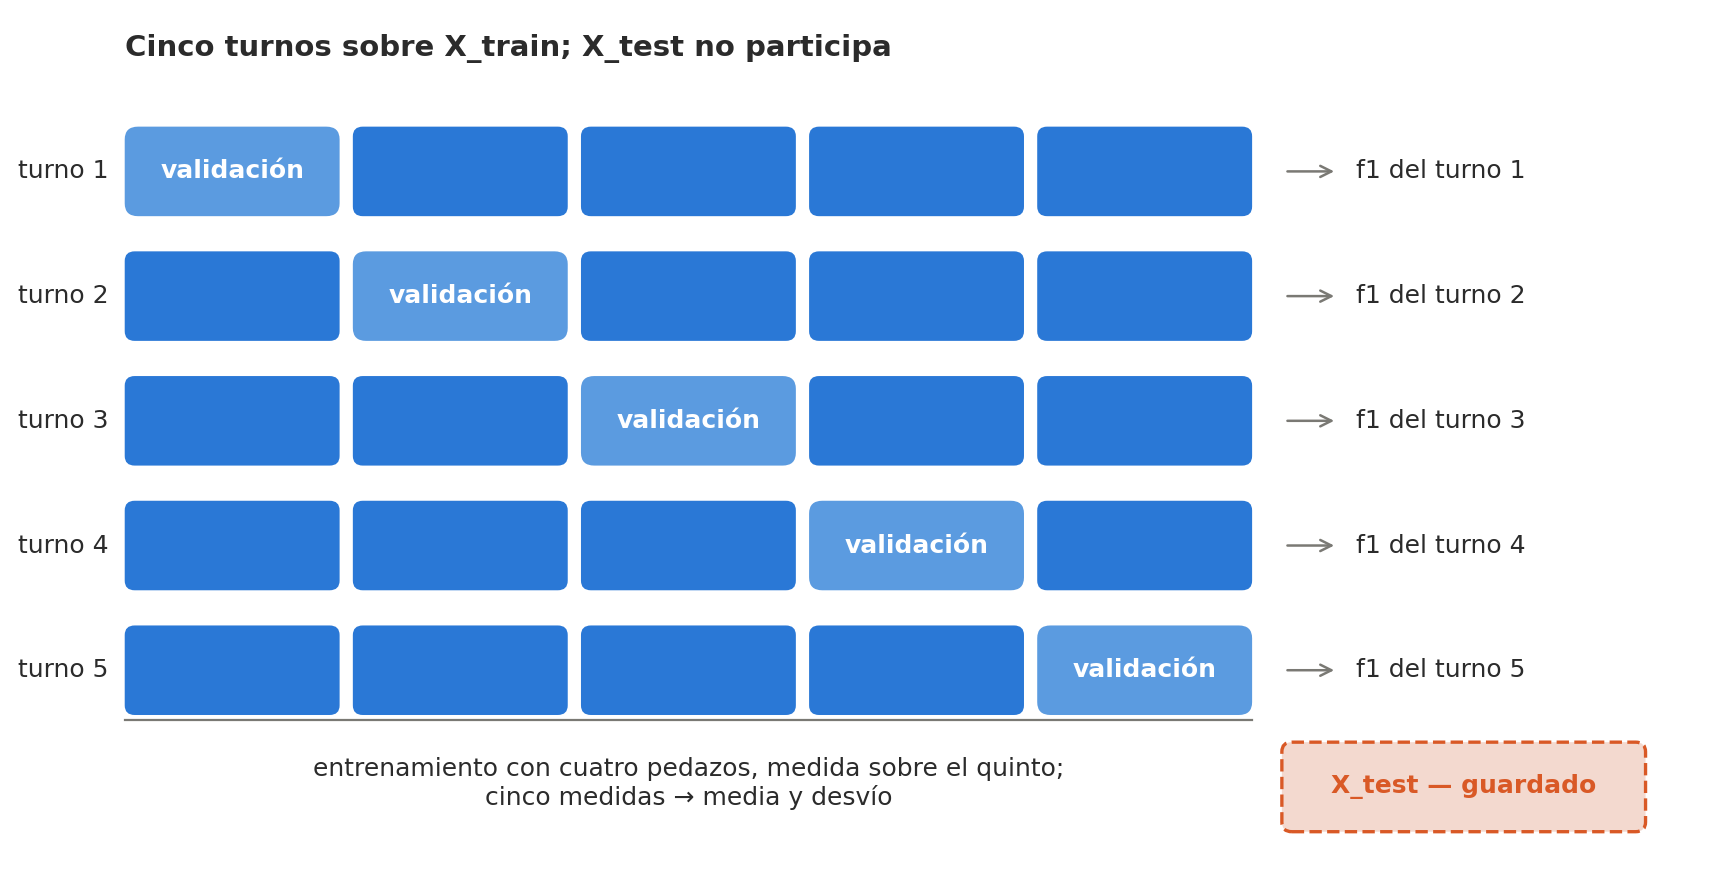

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

# los cinco cortes: cuánto entrena y cuánto valida cada uno
pd.DataFrame([{"entrena con": len(e), "valida sobre": len(v)} for e, v in cv.split(X_train, y_train)],
             index=[f"fold {i + 1}" for i in range(5)])

,entrena con,valida sobre
fold 1,12118,3030
fold 2,12118,3030
fold 3,12118,3030
fold 4,12119,3029
fold 5,12119,3029


In [ ]:
# la logística, cinco veces
puntajes = cross_val_score(logistica, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)

pd.Series(puntajes, index=[f"fold {i + 1}" for i in range(5)]).round(3)

,0
fold 1,0.815
fold 2,0.827
fold 3,0.843
fold 4,0.838
fold 5,0.827


In [ ]:
# el número que importa: media y desvío
pd.Series({"media": puntajes.mean(), "desvío": puntajes.std()}).round(3)

,0
media,0.83
desvío,0.01


Cinco números entre 0,815 y 0,839. La media, 0,830, es lo que vale informar; el desvío, 0,009, es la
**barra de error** del modelo sobre estos datos. Y `cross_val_score` recibió el pipeline entero:
en cada fold se reentrenaron el imputador, el escalador y el one-hot sobre los cuatro pedazos de
entrenamiento, sin que hiciera falta escribir nada. Es la propiedad de la sección 3.2 de la
Práctica 1, cobrada.

### 2.2 Comparar modelos con barra de error

Ahora sí se puede contestar si la logística es *mejor* que el boosting, o si la diferencia de la
Práctica 1 era ruido de partición. La misma validación cruzada para los cuatro modelos; tarda
alrededor de un minuto, casi todo en el bosque.

In [ ]:
from sklearn.model_selection import cross_validate

comparacion = {}
for nombre, p in pipelines.items():
    if nombre == "piso":
        continue
    r = cross_validate(p, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    comparacion[nombre] = {"f1 medio": r["test_score"].mean(), "desvío": r["test_score"].std(),
                           "segundos por fold": r["fit_time"].mean()}

pd.DataFrame(comparacion).T.round(3)

,f1 medio,desvío,segundos por fold
regresión logística,0.830,0.010,3.050
árbol de decisión,0.709,0.009,1.268
random forest,0.749,0.006,21.782
gradient boosting,0.803,0.008,9.739


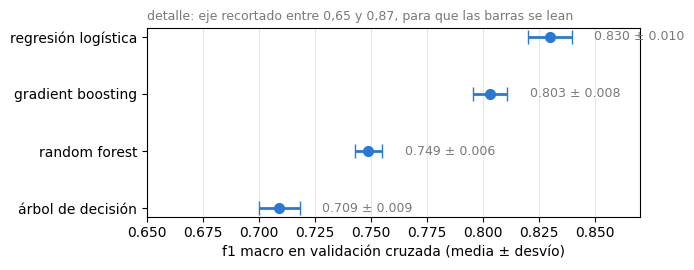

In [ ]:
# la misma tabla, dibujada: el punto es la media y la barra, un desvío a cada lado
tabla_cv = pd.DataFrame(comparacion).T.sort_values("f1 medio")

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.errorbar(tabla_cv["f1 medio"], tabla_cv.index, xerr=tabla_cv["desvío"], fmt="o", color="#2a78d6",
            ecolor="#2a78d6", elinewidth=2, capsize=5, markersize=7)
for nombre, fila in tabla_cv.iterrows():
    ax.text(fila["f1 medio"] + fila["desvío"] + 0.01, nombre, f"{fila['f1 medio']:.3f} ± {fila['desvío']:.3f}",
            va="center", ha="left", fontsize=9, color="#7a7974")
ax.set_xlabel("f1 macro en validación cruzada (media ± desvío)")
ax.set_xlim(0.65, 0.87)
ax.set_title("detalle: eje recortado entre 0,65 y 0,87, para que las barras se lean", fontsize=9, color="#7a7974", loc="left")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

La logística le saca casi tres centésimas al boosting, y el desvío de los dos es de una
centésima: la diferencia es tres veces la barra de error, así que **es real**, no ruido de
partición. Al bosque le saca ocho. El orden de la Práctica 1 se confirma, y ahora con evidencia.

Regla para el resto de la unidad y para la entrega: **dos modelos se comparan por validación
cruzada, con su desvío al lado.** Una diferencia menor que el desvío no es una diferencia; en el
gráfico, dos barras que se superponen son dos modelos que no se distinguen.

Una nota sobre el gráfico: el eje no arranca en cero. Con el eje entero las barras de ±0,009
quedarían del tamaño del punto y no se podría ver si se superponen, que es lo único que el gráfico
tiene que mostrar. Recortar el eje es legítimo en un gráfico de puntos **si se dice en el gráfico
mismo**; recortarlo sin avisar es la forma más común de hacer que una diferencia chica parezca
grande, y en la Unidad 4 vuelve como tema. Y el
costo también cuenta: el bosque tarda seis veces más que la logística por cada fold, para dar
menos.

## Parte 3 — Complejidad: la curva que dibuja la teoría

La teórica de hoy tiene un gráfico: el error de entrenamiento baja siempre con la complejidad
del modelo, y el error de validación baja hasta un punto y después vuelve a subir. Eso se dibuja
con nuestros datos, y la herramienta es la misma validación cruzada aplicada a cada valor de un
hiperparámetro.

In [ ]:
from sklearn.model_selection import validation_curve

def curva(pipeline, parametro, valores, ax, titulo):
    '''Dibuja f1 macro en train y en validación cruzada para cada valor del hiperparámetro.'''
    tr, va = validation_curve(pipeline, X_train, y_train, param_name=parametro, param_range=valores,
                              cv=cv, scoring="f1_macro", n_jobs=-1)
    etiquetas = [str(v) for v in valores]
    ax.plot(etiquetas, tr.mean(axis=1), marker="o", color="#7a7974", label="entrenamiento")
    ax.plot(etiquetas, va.mean(axis=1), marker="o", color="#2a78d6", label="validación cruzada")
    ax.fill_between(etiquetas, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1),
                    color="#2a78d6", alpha=0.15)
    ax.set_title(titulo); ax.set_ylabel("f1 macro"); ax.set_ylim(0, 1.02); ax.legend(loc="lower right")
    return pd.DataFrame({"train": tr.mean(axis=1), "cv": va.mean(axis=1)}, index=etiquetas).round(3)

### 3.1 La profundidad del árbol

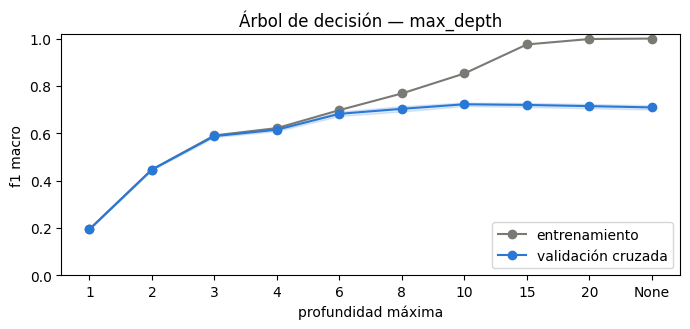

In [ ]:
profundidades = [1, 2, 3, 4, 6, 8, 10, 15, 20, None]

fig, ax = plt.subplots(figsize=(7, 3.4))
curva_arbol = curva(arbol, "clasificador__max_depth", profundidades, ax, "Árbol de decisión — max_depth")
ax.set_xlabel("profundidad máxima")
plt.tight_layout()
plt.show()

In [ ]:
# los números detrás del gráfico
curva_arbol.T

,1,2,3,4,6,8,10,15,20,None
train,0.194,0.446,0.591,0.622,0.698,0.768,0.852,0.975,0.998,1.000
cv,0.194,0.446,0.588,0.615,0.682,0.703,0.722,0.720,0.715,0.709


Es el gráfico de la teórica, con dos cosas que sólo se ven en los datos. Hasta profundidad 6
las dos curvas van juntas: el árbol es demasiado simple para memorizar y demasiado simple para
acertar —**sesgo**—. Desde 8 se separan: entrenamiento sigue subiendo hasta 1,000 y validación
se clava en 0,72 y empieza a bajar —**varianza**—. El mejor árbol posible está en profundidad 10,
y da 0,722. Eso está diez puntos abajo de la logística: **limitar el árbol arregla la
memorización, no el techo.**

### 3.2 La cantidad de árboles del bosque

Un random forest promedia árboles sin límite de profundidad, cada uno entrenado sobre una
muestra distinta. El promedio baja la varianza: la pregunta es cuántos árboles hacen falta, y qué
pasa después.

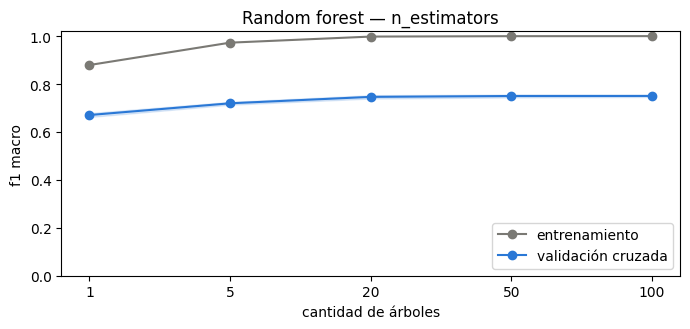

In [ ]:
cantidades = [1, 5, 20, 50, 100]

fig, ax = plt.subplots(figsize=(7, 3.4))
curva_bosque = curva(bosque, "clasificador__n_estimators", cantidades, ax, "Random forest — n_estimators")
ax.set_xlabel("cantidad de árboles")
plt.tight_layout()
plt.show()

In [ ]:
curva_bosque.T

,1,5,20,50,100
train,0.879,0.973,0.998,1.00,1.00
cv,0.671,0.720,0.746,0.75,0.75


Un solo árbol da 0,67 en validación; veinte, 0,75; cincuenta, lo mismo; cien, lo mismo — y los
300 de la tabla de 2.2 dieron 0,749. Promediar árboles arregla lo que un árbol solo tiene de
varianza, y después de veinte no queda nada más que arreglar. El bosque también tiene techo, y
está en 0,75.

### 3.3 La regularización de la logística

La logística no tiene profundidad ni cantidad de árboles. Su hiperparámetro de complejidad es
`C`, y vale la pena ver de dónde sale. Entrenar una regresión logística es encontrar los pesos
$w$ que hacen mínima esta cantidad:

$$
\underbrace{\sum_{i} \text{pérdida}(y_i,\ p_i)}_{\text{qué tan mal predice}}
\;+\;
\frac{1}{C}\;\underbrace{\sum_{j} w_j^{2}}_{\text{qué tan grandes son los pesos}}
$$

El primer término es la log-loss de la teórica, sumada sobre los jugadores de entrenamiento: baja
cuando el modelo acierta. El segundo es una **multa por pesos grandes**, y `C` es lo que la
regula: con `C` chico la multa es cara y los pesos se quedan cerca de cero —el modelo se vuelve
más simple, más chato—; con `C` grande la multa es barata y los pesos crecen hasta donde los datos
los lleven. Es la **regularización**: en vez de limitar cuántas columnas puede usar el modelo,
como hace `max_depth` con el árbol, limita cuánto puede apoyarse en cada una. Y es el motivo de
fondo del `StandardScaler` de la Práctica 1: la multa es sobre el tamaño de los pesos, así que
sólo es justa si todas las columnas están en la misma escala.

Es la misma curva de las dos secciones anteriores, para el modelo que hasta ahora no mostró
sobreajuste.

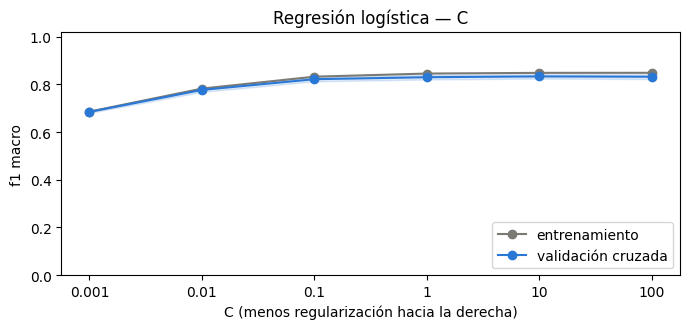

In [ ]:
valores_C = [0.001, 0.01, 0.1, 1, 10, 100]

fig, ax = plt.subplots(figsize=(7, 3.4))
curva_C = curva(logistica, "clasificador__C", valores_C, ax, "Regresión logística — C")
ax.set_xlabel("C (menos regularización hacia la derecha)")
plt.tight_layout()
plt.show()

In [ ]:
curva_C.T

,0.001,0.01,0.1,1,10,100
train,0.686,0.782,0.832,0.845,0.848,0.848
cv,0.684,0.777,0.822,0.830,0.833,0.832


Con `C=0.001` los pesos están tan apretados que el modelo casi no puede distinguir roles: 0,68.
Desde `C=0.1` la curva se aplana, y entre 1 y 100 no cambia nada que supere el desvío. La
logística no necesita que la frenen en este problema, porque **no estaba sobreajustando**: su
brecha en la tabla de 1.1 era de 0,017. Regularizar sirve cuando hay varianza que quitar, y acá no
la hay.

Las tres curvas juntas contestan la primera pregunta de la Práctica 1: ningún modelo de árboles
pasa de 0,75 por más que se lo ajuste, y la logística no necesita ajuste. La regla que se lleva al
integrador: **el modelo más complejo no es el mejor por defecto.** Se prueba el simple primero, se
mide con validación cruzada, y el complejo tiene que ganarle por más que el desvío para justificar
su costo.

## Parte 4 — Tuneo: la búsqueda sobre el pipeline entero

Las curvas de la Parte 3 mueven un hiperparámetro por vez. `GridSearchCV` los mueve todos a la
vez: recibe el pipeline, una grilla de valores, y prueba cada combinación con validación cruzada.
Se escribe con los nombres de doble guión bajo de la sección 3.5 de la Práctica 1, y por eso
puede llegar hasta `relativo`, el hiperparámetro de nuestra propia clase.

### 4.1 Cuatro grillas, una por familia

Se ajustan los cuatro modelos, no sólo el que va ganando. Es la única forma de saber si el orden
de la Parte 2 es de las familias o de los valores por defecto: un bosque mal configurado puede
perder contra una logística bien configurada, y al revés. Cada grilla mueve los dos o tres
hiperparámetros que la Parte 3 mostró que importan; para la logística entra además
`class_weight`, que es nuevo, y `relativo`, el hiperparámetro de nuestra propia clase.

In [ ]:
from sklearn.model_selection import GridSearchCV

grillas = {
    "regresión logística": {"clasificador__C":                [0.1, 1, 10],
                            "clasificador__class_weight":     [None, "balanced"],
                            "derivar__relativo":              [False, True]},
    "árbol de decisión":   {"clasificador__max_depth":        [6, 10, 15],
                            "clasificador__min_samples_leaf": [1, 10, 30]},
    "random forest":       {"clasificador__n_estimators":     [50, 200],
                            "clasificador__max_depth":        [None, 15],
                            "clasificador__max_features":     ["sqrt", 0.3]},
    "gradient boosting":   {"clasificador__learning_rate":    [0.05, 0.2],
                            "clasificador__max_iter":         [100, 300],
                            "clasificador__max_leaf_nodes":   [15, 63]}}

# cuántos entrenamientos son: combinaciones × cinco folds
pd.Series({nombre: int(np.prod([len(v) for v in g.values()])) * 5 for nombre, g in grillas.items()}, name="entrenamientos")

,entrenamientos
regresión logística,60
árbol de decisión,45
random forest,40
gradient boosting,40


`class_weight="balanced"` le da a cada clase un peso inverso a su frecuencia; qué significa eso y
qué cuesta es el tema de la Parte 6. Por ahora es un valor más de la grilla.

Son 185 entrenamientos. Tarda unos minutos, casi todo en el bosque y el boosting.

In [ ]:
busquedas = {}
for nombre, grilla in grillas.items():
    busquedas[nombre] = GridSearchCV(pipelines[nombre], grilla, cv=cv, scoring="f1_macro",
                                     n_jobs=-1, return_train_score=True).fit(X_train, y_train)

# el mejor de cada familia, con su barra de error y lo que daba por defecto
pd.DataFrame({nombre: {"por defecto (2.2)": comparacion[nombre]["f1 medio"],
                       "mejor de la grilla": b.best_score_,
                       "desvío":             b.cv_results_["std_test_score"][b.best_index_]}
              for nombre, b in busquedas.items()}).T.round(3)

,por defecto (2.2),mejor de la grilla,desvío
regresión logística,0.830,0.833,0.009
árbol de decisión,0.709,0.728,0.011
random forest,0.749,0.760,0.006
gradient boosting,0.803,0.811,0.006


In [ ]:
# con qué hiperparámetros llegó cada uno a su mejor
pd.DataFrame({nombre: {k.split("__")[-1]: v for k, v in b.best_params_.items()} for nombre, b in busquedas.items()}).T.fillna("")

,C,class_weight,relativo,max_depth,min_samples_leaf,max_features,n_estimators,learning_rate,max_iter,max_leaf_nodes
regresión logística,10,,False,,,,,,,
árbol de decisión,,,,15.0,10.0,,,,,
random forest,,,,15.0,,0.3,50.0,,,
gradient boosting,,,,,,,,0.05,300.0,15.0


El ajuste movió poco a todos: dos milésimas la logística, dos centésimas el árbol, una el bosque
y el boosting, todo dentro de una o dos barras de error. Y el orden es el mismo de la Parte 2:
**ajustar no cambió quién gana, sólo confirmó que ninguno estaba mal configurado**. Esa es la
respuesta a la pregunta de la Parte 3, ahora con los cuatro en igualdad de condiciones.

### 4.2 Leer la tabla entera, no sólo el ganador

`best_params_` dice quién ganó. `cv_results_` dice **por cuánto**, y es lo que hay que mirar
antes de creerle. La tabla de la logística, completa:

In [ ]:
def tabla_de(busqueda):
    # cv_results_ reducido a lo que se lee: hiperparámetros, media y desvío en validación, media en train
    r = pd.DataFrame(busqueda.cv_results_)
    params = [c for c in r.columns if c.startswith("param_")]
    t = r[params + ["mean_test_score", "std_test_score", "mean_train_score"]]
    return (t.rename(columns=lambda c: c.split("__")[-1].replace("param_", ""))
             .sort_values("mean_test_score", ascending=False))

tabla_de(busquedas["regresión logística"]).round(3)

,C,class_weight,relativo,mean_test_score,std_test_score,mean_train_score
8,10.0,None,False,0.833,0.009,0.848
4,1.0,None,False,0.830,0.010,0.845
5,1.0,None,True,0.829,0.011,0.845
9,10.0,None,True,0.828,0.008,0.849
7,1.0,balanced,True,0.824,0.008,0.836
11,10.0,balanced,True,0.824,0.008,0.840
6,1.0,balanced,False,0.822,0.009,0.835
0,0.1,None,False,0.822,0.009,0.832
10,10.0,balanced,False,0.821,0.007,0.838
1,0.1,None,True,0.821,0.009,0.832


Doce combinaciones entre 0,814 y 0,832, con desvíos de 0,01. El ganador (`C=10`, sin balancear,
sin `relativo`) le saca dos milésimas al segundo y una centésima al noveno: **casi toda la tabla es
un empate**. Sólo `C=0.1` se queda atrás de forma clara, y ya lo sabíamos por la curva de 3.3.

De la tabla salen tres respuestas que la Práctica 1 dejó pendientes: `relativo` no sirve (las dos
versiones empatan en cada fila), `C` no importa mientras no sea chico, y `class_weight="balanced"`
**baja** el f1 macro un poco. Esto último sorprende, y la Parte 6 lo desarma.

La del boosting, que es la que más se mueve, muestra lo otro que se lee en una grilla: la columna
de train.

In [ ]:
tabla_de(busquedas["gradient boosting"]).round(3)

,learning_rate,max_iter,max_leaf_nodes,mean_test_score,std_test_score,mean_train_score
2,0.05,300,15,0.811,0.006,0.980
0,0.05,100,15,0.805,0.007,0.955
1,0.05,100,63,0.803,0.007,0.983
3,0.05,300,63,0.803,0.007,0.983
4,0.20,100,15,0.803,0.009,0.982
6,0.20,300,15,0.803,0.009,0.982
5,0.20,100,63,0.799,0.009,0.983
7,0.20,300,63,0.799,0.009,0.983


Todas las combinaciones memorizan casi todo el entrenamiento (train arriba de 0,95) y ninguna pasa
de 0,82 en validación: la brecha no se cierra moviendo hiperparámetros, porque el techo es de la
familia. Y entre la primera y la última hay una centésima con desvíos de casi una: también acá la
mitad de la tabla es un empate.

Si la grilla fuera más grande —cinco hiperparámetros con cinco valores son 3.125 combinaciones—
se prueba una muestra al azar de ella en vez de toda: `RandomizedSearchCV` recibe el mismo
pipeline y la misma grilla, más `n_iter`, y suele encontrar casi lo mismo en una fracción del
tiempo, porque en casi toda grilla sólo uno o dos hiperparámetros importan.

### 4.3 El test se toca una vez

`GridSearchCV` reentrena el mejor pipeline de cada grilla sobre todo el entrenamiento y lo deja
en `best_estimator_`. Recién ahora, con la decisión tomada —la familia y sus hiperparámetros, por
validación cruzada—, se mira el test. Una vez.

In [ ]:
# el ganador entre los cuatro ganadores, sobre el test que nadie miró hasta acá
mejor_familia = max(busquedas, key=lambda n: busquedas[n].best_score_)
busqueda      = busquedas[mejor_familia]

pd.Series({"familia":                  mejor_familia,
           "f1 en validación cruzada": round(busqueda.best_score_, 3),
           "f1 en el test":            round(f1(busqueda.best_estimator_, X_test, y_test), 3)})

,0
familia,regresión logística
f1 en validación cruzada,0.833
f1 en el test,0.831


Coinciden, y eso es lo que tiene que pasar cuando la búsqueda fue honesta. La trampa es la otra:
probar las doce combinaciones **mirando el test**, quedarse con la mejor, e informar ese número.
Con doce intentos y un desvío de 0,01, el máximo de doce números ruidosos es sistemáticamente
más alto que el verdadero: el test dejaría de medir y pasaría a ser un fold más de la búsqueda.

Cuánto más alto se mide sin entrenar un solo modelo: doce números al azar alrededor de 0,830 con
desvío 0,010, como los de la tabla, y nos quedamos con el máximo. Mil veces.

In [ ]:
# la trampa, simulada: el máximo de doce medidas ruidosas del mismo modelo
rng = np.random.default_rng(SEMILLA)
maximos = rng.normal(0.830, 0.010, size=(1000, 12)).max(axis=1)

pd.Series({"valor real": 0.830, "máximo de doce, en promedio": maximos.mean()}).round(3)

,0
valor real,0.830
"máximo de doce, en promedio",0.846


Elegir el mejor de doce sobre el test regala una centésima y media que no existe — más que la
diferencia entre el primero y el noveno de la grilla. No es que el test mienta: es que se lo usó
para elegir, y una medida que se usó para elegir ya no mide.

Regla: **todo lo que se elige —modelo, hiperparámetros, umbrales, columnas— se elige por
validación cruzada sobre el entrenamiento. El test se mira una vez, al final, para informar.**
Si después de mirarlo se cambia algo, ya no es un test.

## Parte 5 — Las columnas que cada modelo necesita

El ajuste de la Parte 4 movió a cada familia una o dos centésimas y no cambió el orden. Hay una
palanca más grande que los hiperparámetros, y la Práctica 1 la dejó a la vista sin usarla: en la
sección 5.2 de aquel notebook, las tres restas de `DiferenciasDeHabilidades` tenían peso casi
nulo en la logística, y el bosque las ponía entre sus columnas más importantes. **El mismo dato
sirve o no según cómo funciona el modelo que lo recibe.** Eso es lo que se gana entendiendo el
modelo en vez de usarlo como caja negra: saber qué darle.

- Una regresión logística sólo puede **sumar columnas con pesos**. Una resta de dos columnas que ya
  tiene no le agrega nada: la podía armar sola con dos pesos. Lo que no puede armar es un máximo,
  un conteo, una dispersión, una curva; si el problema los necesita, hay que dárselos hechos.
- Un árbol sólo puede **preguntar por una columna a la vez, con un umbral**. Para expresar
  «defiende más de lo que ataca» necesita partir muchas veces por `defending` y por `shooting`,
  en escalera; con la resta hecha, es una sola pregunta. Lo que no necesita son curvas: un umbral
  sobre `x` y uno sobre `x²` son la misma pregunta.

Eso se mide. Con pipelines separados, el paso `derivar` puede ser distinto para cada modelo, y la
validación cruzada dice qué le conviene a cada uno. Primero hace falta una versión de `armar` que
acepte cualquier `derivar` y averigüe sola qué columnas nuevas produce, numéricas o categóricas,
para que `preparar` las reciba.

In [ ]:
def armar_con(clasificador, derivar):
    '''El pipeline de siempre con el paso derivar que se le pase; preparar se entera de las columnas nuevas.'''
    muestra     = clone(derivar).fit_transform(X_train.head(500), y_train.head(500))
    nuevas      = [c for c in muestra.columns if c not in X_train.columns]
    nuevas_num  = [c for c in nuevas if pd.api.types.is_numeric_dtype(muestra[c])]
    nuevas_cat  = [c for c in nuevas if c not in nuevas_num]
    prep = ColumnTransformer([
        ("numericas", Pipeline([("imputar", SimpleImputer(strategy="median")),
                                ("escalar", StandardScaler())]),
         NUMERICAS + nuevas_num),
        ("categoricas", Pipeline([("imputar",   SimpleImputer(strategy="most_frequent")),
                                  ("codificar", OneHotEncoder(handle_unknown="ignore"))]),
         CATEGORICAS + nuevas_cat)])
    return Pipeline([("derivar", derivar), ("preparar", prep), ("clasificador", clasificador)])


def medir(pipeline):
    '''f1 macro por validación cruzada: media y desvío.'''
    puntajes = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    return {"f1 medio": puntajes.mean(), "desvío": puntajes.std()}


class Nada(BaseEstimator, TransformerMixin):
    '''El paso derivar que no deriva: la referencia contra la que se mide todo lo demás.'''
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X

HABILIDADES = ["pace", "shooting", "passing", "dribbling", "defending", "physic"]

### 5.1 Lo que un modelo lineal no puede calcular

Tres ideas futboleras que una suma con pesos no puede expresar, en un solo transformador con la
receta de la sección 2.7 de la Práctica 1:

- **La habilidad dominante.** Cuál de las seis es la más alta. Es un *argmax*, y sale como columna
  categórica: `shooting` casi dice delantero, `defending` casi dice central.
- **La dispersión.** El desvío estándar de las seis: el especialista contra el todoterreno. Separa
  *qué tipo* de jugador de *qué nivel*.
- **El conteo.** Cuántas habilidades tiene por encima de 70. Una suma de indicadores no es lineal
  en las habilidades.

Y una cuarta de otra clase: la **altura** importa, pero no en línea recta —muy alto empuja a
central o arquero, muy bajo a extremo, y el medio no dice nada—. `SplineTransformer` convierte
una columna en varias curvas suaves, y con eso la logística puede dibujar la forma que sola no
puede. Se aplica a altura, peso y edad.

In [ ]:
from sklearn.preprocessing import SplineTransformer

class Perfil(BaseEstimator, TransformerMixin):
    '''Agrega la habilidad dominante (categórica), la dispersión de las seis y cuántas superan 70.'''

    def __init__(self, umbral=70):
        self.umbral = umbral

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        h = X[HABILIDADES]
        # los arqueros no tienen las seis habilidades: su dominante es «ninguna»
        dominante = h.fillna(-1).idxmax(axis=1).where(h.notna().any(axis=1), "ninguna")
        nuevas = pd.DataFrame({"habilidad_dominante": dominante,
                               "dispersion":          h.std(axis=1),
                               "habilidades_altas":   (h > self.umbral).sum(axis=1)}, index=X.index)
        return pd.concat([X, nuevas], axis=1)


class Curvas(BaseEstimator, TransformerMixin):
    '''Reemplaza cada columna indicada por sus curvas de spline; lo que la logística no puede dibujar sola.'''

    def __init__(self, columnas=("height_cm", "weight_kg", "age"), n_knots=6):
        self.columnas = columnas
        self.n_knots = n_knots

    def fit(self, X, y=None):
        self.medianas_ = X[list(self.columnas)].median()
        self.spline_ = SplineTransformer(n_knots=self.n_knots).set_output(transform="pandas")
        self.spline_.fit(X[list(self.columnas)].fillna(self.medianas_))
        return self

    def transform(self, X):
        curvas = self.spline_.transform(X[list(self.columnas)].fillna(self.medianas_))
        curvas.index = X.index
        return pd.concat([X, curvas], axis=1)


# qué produce cada uno, sobre cinco jugadores
Perfil().fit_transform(X_train.head(5))[["overall"] + HABILIDADES + ["habilidad_dominante", "dispersion", "habilidades_altas"]].round(1)

,overall,pace,shooting,passing,dribbling,defending,physic,habilidad_dominante,dispersion,habilidades_altas
14910,70,73,68,67,70,65,81,physic,5.8,2
1687,83,89,83,75,85,34,71,pace,20.1,5
5228,75,77,68,71,78,67,76,dribbling,4.8,4
13432,71,74,65,67,74,66,69,pace,4.0,2
387,73,87,69,65,74,47,78,pace,13.6,3


In [ ]:
# las curvas de la altura: ocho columnas que valen entre 0 y 1, cada una «encendida» en un rango de alturas
Curvas(columnas=("height_cm",)).fit_transform(X_train.head(5)).filter(like="height_cm").round(2)

,height_cm,height_cm_sp_0,height_cm_sp_1,height_cm_sp_2,height_cm_sp_3,height_cm_sp_4,height_cm_sp_5,height_cm_sp_6,height_cm_sp_7
14910,173,0.00,0.12,0.66,0.23,0.00,0.00,0.00,0.00
1687,183,0.00,0.00,0.00,0.00,0.23,0.66,0.12,0.00
5228,187,0.00,0.00,0.00,0.00,0.00,0.17,0.67,0.17
13432,169,0.17,0.67,0.17,0.00,0.00,0.00,0.00,0.00
387,180,0.00,0.00,0.00,0.14,0.66,0.20,0.00,0.00


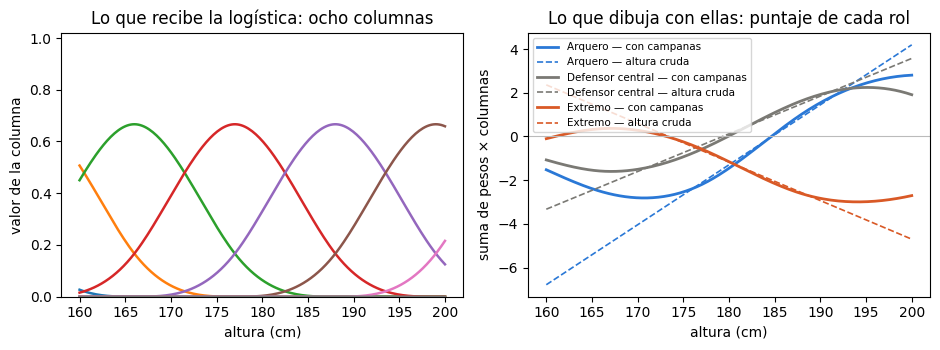

In [ ]:
# las ocho campanas sobre toda la escala de alturas, y qué hace la logística con ellas
alturas       = pd.DataFrame({"height_cm": np.linspace(160, 200, 200)})
curvas_altura = Curvas(columnas=("height_cm",)).fit(X_train)
campanas      = curvas_altura.transform(alturas).filter(like="_sp_")

# dos logísticas que sólo ven la altura: una cruda, otra en campanas
solo_altura   = LogisticRegression(max_iter=3000).fit(X_train[["height_cm"]], y_train)
solo_campanas = LogisticRegression(max_iter=3000).fit(curvas_altura.transform(X_train).filter(like="_sp_"), y_train)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.6))
for j, columna in enumerate(campanas.columns):
    ax1.plot(alturas["height_cm"], campanas[columna], lw=1.8, label=f"campana {j}")
ax1.set_title("Lo que recibe la logística: ocho columnas"); ax1.set_xlabel("altura (cm)"); ax1.set_ylabel("valor de la columna")
ax1.set_ylim(0, 1.02)

# el puntaje de cada rol antes de convertirlo en probabilidad: la suma de pesos por columnas
roles = {"Arquero": "#2a78d6", "Defensor central": "#7a7974", "Extremo": "#d95926"}
z_cruda    = pd.DataFrame(solo_altura.decision_function(alturas),    columns=solo_altura.classes_)
z_campanas = pd.DataFrame(solo_campanas.decision_function(campanas), columns=solo_campanas.classes_)
for rol, color in roles.items():
    ax2.plot(alturas["height_cm"], z_campanas[rol], color=color, lw=2, label=f"{rol} — con campanas")
    ax2.plot(alturas["height_cm"], z_cruda[rol],    color=color, lw=1.2, ls="--", label=f"{rol} — altura cruda")
ax2.set_title("Lo que dibuja con ellas: puntaje de cada rol"); ax2.set_xlabel("altura (cm)"); ax2.set_ylabel("suma de pesos × columnas")
ax2.axhline(0, color="#bbbbbb", lw=0.8); ax2.legend(fontsize=7.5, loc="upper left")
plt.tight_layout()
plt.show()

A la izquierda, lo que recibe: ocho campanas, cada una encendida en un rango de alturas, con
valores entre 0 y 1 que suman uno en cada punto. A la derecha, lo que hace con ellas una logística
que **sólo ve la altura**: el puntaje de cada rol antes de convertirlo en probabilidad, que es la
suma de pesos por columnas de la sección 3.3. Con la altura cruda (punteada) ese puntaje es una
recta, porque es un peso por una columna: más alto, más arquero, sin matices. Con las campanas
(llena) es una curva: el puntaje de Defensor central sube hasta 1,90 y después baja, el de Extremo
cae fuerte entre 1,75 y 1,90 y se aplana. La logística no cambió; cambió lo que le dieron para
sumar. Ahora se mide, con la logística que ganó su grilla.

In [ ]:
variantes_lineal = {"sin columnas nuevas": Nada(),
                    "perfil":             Perfil(),
                    "curvas":             Curvas(),
                    "perfil y curvas":    Pipeline([("perfil", Perfil()), ("curvas", Curvas())])}

lineal_cv = {variante: medir(armar_con(LogisticRegression(max_iter=3000, C=10), clone(derivar)))
             for variante, derivar in variantes_lineal.items()}

tabla_lineal = pd.DataFrame(lineal_cv).T
tabla_lineal.assign(ganancia=tabla_lineal["f1 medio"] - tabla_lineal.loc["sin columnas nuevas", "f1 medio"]).round(3)

,f1 medio,desvío,ganancia
sin columnas nuevas,0.832,0.009,0.000
perfil,0.832,0.007,-0.001
curvas,0.838,0.007,0.006
perfil y curvas,0.840,0.007,0.007


Es la primera vez en todo el notebook que algo le gana a la logística de la Práctica 1, y no fue
un modelo: fue una curva. El perfil solo casi no mueve —la habilidad dominante y la dispersión
son cosas que la logística ya resolvía con sus pesos sobre las seis habilidades—, pero las curvas
de altura, peso y edad suman seis milésimas, y las dos juntas siete, con el desvío más chico de
la tabla. Es poco más que una barra de error, y es más que toda la grilla de la Parte 4.

La lección no es «usar splines»: es que **cuando el modelo lineal está en su techo, lo que falta
no es un modelo más grande sino la forma que no puede dibujar**. Acá la forma era la altura; en
otro problema será una edad, un precio, una fecha.

### 5.2 Lo que un árbol no puede calcular

Para los árboles la carencia es la opuesta: **fronteras oblicuas**, las que combinan columnas.
La forma más simple de dárselas son **las restas** entre las seis habilidades resumen: quince
columnas, cada una una comparación hecha —«defiende más de lo que ataca»— que al árbol le ahorra
la escalera. Y como las seis resumen son promedios de las veintinueve habilidades detalladas
(`attacking_finishing`, `mentality_interceptions`, `power_strength`…), se puede ir un nivel más
abajo: **las 406 restas** entre todas las detalladas. Se mide sobre el árbol y el boosting, cada
uno con los hiperparámetros que ganaron su grilla; el bosque queda afuera porque tarda y se parece
al boosting.

In [ ]:
class Diferencias(BaseEstimator, TransformerMixin):
    '''Agrega una columna a_menos_b por cada par (a, b).'''

    def __init__(self, pares=()):
        self.pares = pares

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        nuevas = {f"{a}_menos_{b}": X[a] - X[b] for a, b in self.pares}
        return pd.concat([X, pd.DataFrame(nuevas, index=X.index)], axis=1)


DETALLADAS = [c for c in NUMERICAS if "_" in c and c != "skill_moves" and c.split("_")[0] in
              {"attacking", "skill", "movement", "power", "mentality", "defending"}]

PARES_RESUMEN    = [(a, b) for i, a in enumerate(HABILIDADES) for b in HABILIDADES[i + 1:]]
PARES_DETALLADAS = [(a, b) for i, a in enumerate(DETALLADAS) for b in DETALLADAS[i + 1:]]
len(PARES_RESUMEN), len(PARES_DETALLADAS)

(15, 406)

In [ ]:
variantes_arbol = {"sin columnas nuevas":          Nada(),
                   "las 15 restas (resumen)":      Diferencias(pares=PARES_RESUMEN),
                   "las 406 restas (detalladas)":  Diferencias(pares=PARES_DETALLADAS)}

ajustados = {"árbol de decisión": lambda: DecisionTreeClassifier(max_depth=15, min_samples_leaf=10, random_state=SEMILLA),
             "gradient boosting": lambda: HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15, random_state=SEMILLA)}

# seis pipelines con validación cruzada; tarda unos minutos, casi todo en el boosting con 406 columnas más
arbol_cv = {(modelo, variante): medir(armar_con(fabricar(), clone(derivar)))
            for modelo, fabricar in ajustados.items() for variante, derivar in variantes_arbol.items()}

tabla_arbol = pd.DataFrame(arbol_cv).T
tabla_arbol.index.names = ["modelo", "variante"]
tabla_arbol.round(3)

f1 medio  desvío
modelo            variante                                     
árbol de decisión sin columnas nuevas             0.726   0.011
                  las 15 restas (resumen)         0.743   0.009
                  las 406 restas (detalladas)     0.775   0.010
gradient boosting sin columnas nuevas             0.812   0.007
                  las 15 restas (resumen)         0.812   0.003
                  las 406 restas (detalladas)     0.826   0.009

In [ ]:
# la misma tabla, leída como ganancia respecto de no agregar nada
ganancia = tabla_arbol["f1 medio"].unstack("variante")[list(variantes_arbol)]
ganancia.sub(ganancia["sin columnas nuevas"], axis=0).round(3)

variante,sin columnas nuevas,las 15 restas (resumen),las 406 restas (detalladas)
modelo,,,
gradient boosting,0.0,0.000,0.014
árbol de decisión,0.0,0.017,0.048


Las quince restas le dan al árbol casi dos centésimas, dos desvíos, más que toda su grilla de la
Parte 4: con las comparaciones hechas, lo que antes necesitaba una escalera de cortes es una
pregunta. Al boosting no le dan nada, y eso también se explica: trescientos árboles chicos en
secuencia ya arman la escalera entre dos columnas sin que nadie se la dé hecha. Lo que el árbol
solo no puede expresar, el conjunto sí.

Las 406 restas detalladas son otra cosa: al árbol le dan **cinco centésimas** (de 0,726 a 0,775) y
al boosting una y media (0,812 a 0,826), que es más que toda su grilla. Si el boosting no
necesitaba que le hicieran la escalera, lo que ganó acá no es la escalera: es **información que
las seis habilidades resumen pierden al promediar**. `shooting` es un promedio de finalización,
potencia de tiro, voleas, cabezazo y penales; un jugador que define mucho mejor de lo que cabecea
y otro con el perfil contrario tienen el mismo `shooting`, y la resta `attacking_finishing −
attacking_heading_accuracy` los separa. La granularidad de las columnas que se combinan importa
tanto como la combinación.

El método es lo que se lleva, y vale para el integrador más que cualquier número de hoy: antes de
tunear, preguntarse **qué no puede expresar este modelo con estas columnas**, construirlo con un
transformador de la receta 2.7, y medir si le sirvió. Al lineal, las formas que no puede dibujar;
al árbol, las combinaciones que no puede sumar. Y la validación cruzada dice si el problema las
pedía; cuando no las pedía —el perfil para la logística, las quince restas para el boosting—
también es un resultado, y se escribe.

## Parte 6 — El desbalance como decisión

Queda la segunda pregunta de la Práctica 1: Extremo, cien jugadores en el test, 0,24 de recall.
La grilla acaba de decir que balancear las clases *baja* el f1 macro, y eso parece contradecir
todo. Antes de mirar qué hace `class_weight`, conviene tener claro cuál es el problema que
intenta resolver.

### 6.1 El problema: la pérdida cuenta jugadores, no clases

In [ ]:
# cuántos jugadores de cada rol hay en el entrenamiento
y_train.value_counts().to_frame("jugadores").assign(proporcion=lambda t: (t["jugadores"] / len(y_train)).round(3))

,jugadores,proporcion
best_position,,
Volante,4922,0.325
Defensor central,3015,0.199
Delantero,2145,0.142
Lateral,1951,0.129
Arquero,1685,0.111
Volante defensivo,1031,0.068
Extremo,399,0.026


Volante tiene doce veces más jugadores que Extremo. Eso es el **desbalance**, y es un problema por
cómo se entrena un modelo, no por cómo se lo mide. La función que la logística minimiza —la de la
sección 3.3— suma la pérdida **de cada jugador**, y todos pesan lo mismo. Un error en un volante
cuesta igual que un error en un extremo; pero hay diez veces más volantes, así que la forma más
barata de bajar la suma es acertar volantes, aunque eso signifique no contestar nunca Extremo. El
modelo no es tonto: está haciendo exactamente lo que se le pidió, y lo que se le pidió fue
minimizar errores *contados por jugador*.

La métrica dice lo contrario: el f1 **macro** promedia las clases, no los jugadores, así que
Extremo vale lo mismo que Volante. El entrenamiento y la evaluación están tirando para lados
distintos. Las dos palancas de esta parte corrigen eso, en dos lugares diferentes:

- **En el entrenamiento**: cambiar cuánto pesa cada jugador en la suma, para que las clases chicas
  cuenten tanto como las grandes. Eso es `class_weight`.
- **En la decisión**: dejar el entrenamiento como está y cambiar la regla con la que el modelo
  convierte probabilidades en una respuesta. Eso es el umbral, de la sección 6.3.

Hay una tercera, que es la misma idea que la primera hecha a mano: copiar jugadores de las clases
chicas o tirar jugadores de las grandes antes de entrenar (*oversampling* y *undersampling*).
Cambiar los datos para no cambiar el modelo es más frágil que pesar la pérdida, y no hace falta
acá; la nombramos porque van a encontrarla.

### 6.2 Lo que `class_weight` cambia, y lo que cuesta

`class_weight="balanced"` multiplica la pérdida de cada jugador por un peso que depende de su
clase: el total de jugadores dividido por la cantidad de clases y por la cantidad de jugadores de
esa clase. Las clases chicas reciben pesos grandes, y la suma de pesos de cada clase queda igual.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

clases = np.sort(y_train.unique())
pd.Series(compute_class_weight("balanced", classes=clases, y=y_train), index=clases, name="peso").round(2)

,peso
Arquero,1.28
Defensor central,0.72
Delantero,1.01
Extremo,5.42
Lateral,1.11
Volante,0.44
Volante defensivo,2.10


Cada extremo cuenta como cinco jugadores y medio; cada volante, como menos de medio. Con eso, en la suma
de la pérdida, Extremo pesa lo mismo que Volante. La logística balanceada es un pipeline más, con
nombre propio, y se compara con la de siempre sobre el test clase por clase.

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

balanceada = armar(LogisticRegression(max_iter=3000, class_weight="balanced")).fit(X_train, y_train)

# el efecto, clase por clase
def por_clase(modelo):
    return pd.DataFrame(classification_report(y_test, modelo.predict(X_test), output_dict=True)).T

pd.concat({"sin balancear": por_clase(logistica)[["precision", "recall"]],
           "balanceada":    por_clase(balanceada)[["precision", "recall"]]}, axis=1).round(3)

sin balancear        balanceada       
                      precision recall  precision recall
Arquero                   1.000  1.000      1.000  1.000
Defensor central          0.950  0.958      0.966  0.943
Delantero                 0.944  0.942      0.940  0.938
Extremo                   0.533  0.240      0.250  0.790
Lateral                   0.895  0.871      0.875  0.891
Volante                   0.863  0.923      0.939  0.719
Volante defensivo         0.805  0.736      0.692  0.915
accuracy                  0.904  0.904      0.863  0.863
macro avg                 0.856  0.810      0.809  0.885
weighted avg              0.899  0.904      0.908  0.863

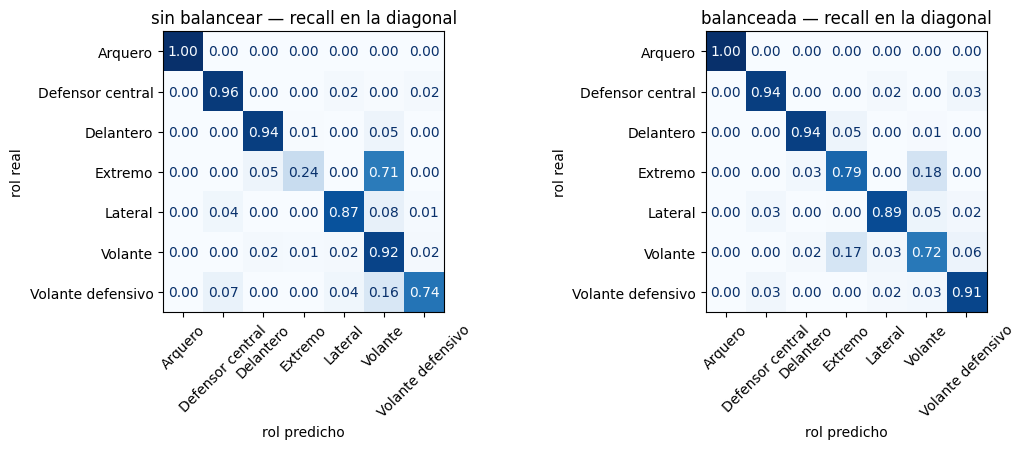

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (nombre, modelo) in zip(axes, [("sin balancear", logistica), ("balanceada", balanceada)]):
    ConfusionMatrixDisplay.from_predictions(y_test, modelo.predict(X_test), ax=ax, cmap="Blues",
                                            colorbar=False, xticks_rotation=45,
                                            normalize="true", values_format=".2f")
    ax.set_title(f"{nombre} — recall en la diagonal")
    ax.set_xlabel("rol predicho"); ax.set_ylabel("rol real")
plt.tight_layout()
plt.show()

In [ ]:
# el resumen: accuracy y f1 macro, antes y después
pd.DataFrame({"sin balancear": {"accuracy": (logistica.predict(X_test) == y_test).mean(),  "f1 macro": f1(logistica, X_test, y_test)},
              "balanceada":    {"accuracy": (balanceada.predict(X_test) == y_test).mean(), "f1 macro": f1(balanceada, X_test, y_test)}}).round(3)

,sin balancear,balanceada
accuracy,0.904,0.863
f1 macro,0.825,0.823


El recall de Extremo pasa de 0,24 a **0,79**: el modelo balanceado encuentra cuatro de cada
cinco extremos. Pero su precision cae de 0,53 a 0,25: de cada cuatro jugadores que llama Extremo,
tres no lo son. Volante es el que lo pierde —de 0,92 a 0,72 de recall— y el volante defensivo
también se mueve. La accuracy baja cuatro puntos y el f1 macro queda igual.

No es una mejora ni un empeoramiento: es un **intercambio**. `class_weight="balanced"` corre la
frontera hacia las clases chicas, y lo que gana en recall lo pierde en precision. Si lo que se
necesita es *no perder ningún extremo* —un scout que después revisa a mano— es la decisión
correcta; si lo que se necesita es *acertar* el rol de cada jugador, no lo es. La métrica que se
declara al principio es la que decide.

### 6.3 La palanca fina: el umbral

`class_weight` mueve todas las fronteras a la vez, y reentrena. Hay una palanca más precisa, que
no toca el entrenamiento: el modelo no contesta un rol, contesta **siete probabilidades**, y
`predict` se queda con la más alta. Esa regla se puede cambiar.

In [ ]:
# lo que el modelo contesta de verdad: una probabilidad por rol
probabilidades = pd.DataFrame(logistica.predict_proba(X_test), columns=logistica[-1].classes_, index=X_test.index)
probabilidades.head(5).round(2).assign(real=y_test.head(5))

,Arquero,Defensor central,Delantero,Extremo,Lateral,Volante,Volante defensivo,real
5060,0.0,0.00,0.00,0.00,0.03,0.01,0.96,Volante defensivo
17988,0.0,0.00,0.00,0.00,0.08,0.73,0.18,Volante defensivo
7083,0.0,0.00,0.34,0.18,0.00,0.48,0.00,Delantero
10593,0.0,0.97,0.00,0.00,0.02,0.00,0.01,Defensor central
5641,0.0,0.00,0.00,0.42,0.00,0.58,0.00,Volante


El último de los cinco tiene 0,42 de Extremo y 0,58 de Volante, y sale Volante. Un extremo con esos
mismos números también saldría Volante, y ahí está el 0,71 de la matriz. Si decidimos que *0,4
alcanza* para contestar Extremo, recuperamos a ese extremo — y nos equivocamos con este volante.
El umbral es un intercambio, como `class_weight`, pero sobre una sola clase.

Y es una decisión más, que se elige como todas: **por validación cruzada, sin mirar el test.**
`cross_val_predict` devuelve las probabilidades de cada jugador del entrenamiento calculadas por
el fold que no lo vio.

In [ ]:
from sklearn.model_selection import cross_val_predict

proba_cv = pd.DataFrame(cross_val_predict(logistica, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1),
                        columns=logistica[-1].classes_, index=X_train.index)

def con_umbral(proba, umbral):
    '''La regla nueva: Extremo si su probabilidad pasa el umbral; si no, la clase más probable.'''
    respuesta = proba.idxmax(axis=1)
    respuesta[proba["Extremo"] >= umbral] = "Extremo"
    return respuesta

# f1 macro en validación cruzada para cada umbral
filas = []
for umbral in [0.5, 0.4, 0.3, 0.25, 0.2, 0.15, 0.1]:
    pred = con_umbral(proba_cv, umbral)
    es_extremo = y_train == "Extremo"
    filas.append({"umbral": umbral,
                  "f1 macro (cv)":     f1_score(y_train, pred, average="macro"),
                  "recall Extremo":    (pred[es_extremo] == "Extremo").mean(),
                  "precision Extremo": (y_train[pred == "Extremo"] == "Extremo").mean()})

pd.DataFrame(filas).set_index("umbral").round(3)

,f1 macro (cv),recall Extremo,precision Extremo
umbral,,,
0.50,0.831,0.258,0.520
0.40,0.834,0.306,0.464
0.30,0.838,0.404,0.411
0.25,0.841,0.481,0.389
0.20,0.841,0.569,0.356
0.15,0.838,0.657,0.320
0.10,0.832,0.769,0.280


Con 0,5 es el modelo de siempre (el `predict` normal). Bajando el umbral el recall de Extremo sube
y la precision baja, como con `class_weight` — pero acá lo demás no se mueve, y el f1 macro
**sube** hasta un máximo en 0,20–0,25 y recién después cae.

La tabla mira siete umbrales. La **curva precision-recall** los mira todos: para cada umbral
posible, qué precision y qué recall tiene Extremo contra el resto. Es el intercambio entero
dibujado, y los siete de la tabla son puntos sobre ella. Al lado, la **curva ROC**, que es la que
más aparece en los libros: recall contra la tasa de falsos positivos (de los que *no* son extremos,
qué fracción se llamó Extremo).

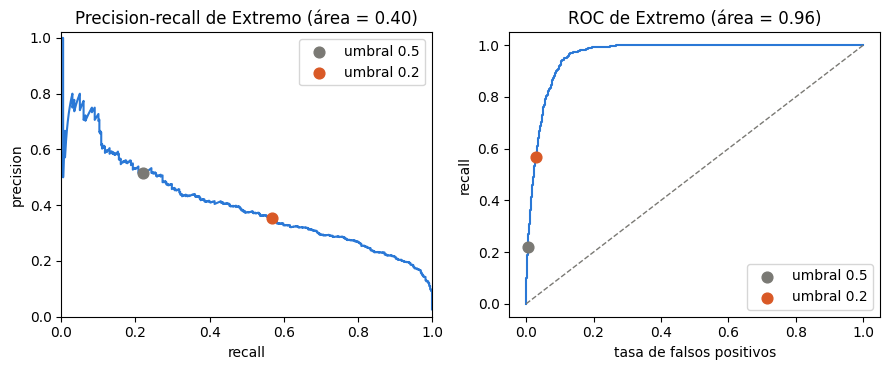

In [ ]:
from sklearn.metrics import precision_recall_curve, roc_curve, average_precision_score, roc_auc_score

es_extremo = (y_train == "Extremo").astype(int)
p_extremo  = proba_cv["Extremo"]

pr_p, pr_r, pr_u = precision_recall_curve(es_extremo, p_extremo)
roc_fpr, roc_tpr, roc_u = roc_curve(es_extremo, p_extremo)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.8))
ax1.plot(pr_r, pr_p, color="#2a78d6")
ax2.plot(roc_fpr, roc_tpr, color="#2a78d6")
ax2.plot([0, 1], [0, 1], color="#7a7974", linestyle="--", linewidth=1)

# los dos umbrales de la tabla, marcados sobre las dos curvas
for umbral, color in [(0.5, "#7a7974"), (0.2, "#d95926")]:
    k = np.argmin(np.abs(pr_u - umbral))
    ax1.scatter(pr_r[k], pr_p[k], color=color, zorder=3, s=60, label=f"umbral {umbral}")
    k = np.argmin(np.abs(roc_u - umbral))
    ax2.scatter(roc_fpr[k], roc_tpr[k], color=color, zorder=3, s=60, label=f"umbral {umbral}")

ax1.set_title(f"Precision-recall de Extremo (área = {average_precision_score(es_extremo, p_extremo):.2f})")
ax1.set_xlabel("recall"); ax1.set_ylabel("precision"); ax1.set_xlim(0, 1); ax1.set_ylim(0, 1.02); ax1.legend()
ax2.set_title(f"ROC de Extremo (área = {roc_auc_score(es_extremo, p_extremo):.2f})")
ax2.set_xlabel("tasa de falsos positivos"); ax2.set_ylabel("recall"); ax2.legend(loc="lower right")
plt.tight_layout()
plt.show()

Las dos curvas cuentan lo mismo con escalas distintas. En la ROC el modelo parece casi perfecto
—área 0,96— porque el eje horizontal divide por los que *no* son extremos, que son casi quince
mil: llamar Extremo a cuatrocientos jugadores que no lo son, como hace el umbral 0,2, es una tasa
de falsos positivos de 0,03, invisible. La curva precision-recall divide por los que el modelo
llamó Extremo, y ahí esos cuatrocientos son dos tercios de la respuesta; su área es 0,41. **Para una clase chica, la curva que informa es la precision-recall**; la
ROC es la que queda bien en el informe.

Lo que sí dicen las dos: el umbral 0,5 está en un rincón de la curva —poco recall, mucha
precision— y 0,2 está en el codo. Elegimos 0,2, por la tabla de arriba, y ahora sí, una sola vez,
el test.

In [ ]:
# el umbral elegido por validación cruzada, aplicado al test
pred_test = con_umbral(probabilidades, 0.2)

pd.Series({"f1 macro con predict":     f1(logistica, X_test, y_test),
           "f1 macro con umbral 0,2":  f1_score(y_test, pred_test, average="macro"),
           "accuracy con umbral 0,2":  (pred_test == y_test).mean()}).round(3)

,0
f1 macro con predict,0.825
"f1 macro con umbral 0,2",0.843
"accuracy con umbral 0,2",0.895


0,844: más de una centésima por encima del mejor pipeline de la grilla, cambiando una regla de una línea
en vez de un modelo. Y la ganancia está donde se buscó: en la clase que el modelo entendía pero
no contestaba.

Es tentador haberlo hecho al revés —probar umbrales sobre el test hasta que el número suba—, y
habría dado el mismo 0,844. La diferencia no está en el número: está en que el nuestro se puede
informar y el otro no.

### 6.4 Qué quiere decir «mejor»

In [ ]:
# tres modelos, tres respuestas a la misma pregunta
def resumen(pred):
    es_extremo = y_test == "Extremo"
    return {"accuracy":         (pred == y_test).mean(),
            "f1 macro":         f1_score(y_test, pred, average="macro"),
            "recall Extremo":   (pred[es_extremo] == "Extremo").mean(),
            "precision Extremo": (y_test[pred == "Extremo"] == "Extremo").mean()}

pd.DataFrame({"el de la grilla": resumen(pd.Series(busqueda.predict(X_test), index=X_test.index)),
              "balanceada":      resumen(pd.Series(balanceada.predict(X_test), index=X_test.index)),
              "con umbral 0,2":  resumen(pred_test)}).T.round(3)

,accuracy,f1 macro,recall Extremo,precision Extremo
el de la grilla,0.905,0.831,0.27,0.562
balanceada,0.863,0.823,0.79,0.250
"con umbral 0,2",0.895,0.843,0.62,0.383


El de la grilla tiene la accuracy más alta y a Extremo casi sin contestar; la balanceada encuentra
cuatro de cada cinco extremos a costa de cuatro puntos de accuracy; el del umbral tiene el f1 macro
más alto, con Extremo a mitad de camino.

Ninguno es «el mejor» hasta que alguien dice para qué. Un modelo que se entrega sin decir con
qué métrica se eligió, y por qué esa, no se puede evaluar. En el TP3 la métrica está declarada
—f1 macro— y por eso hay una respuesta; en el integrador la declarás vos, y es la primera pregunta
de la Entrega 3.

## Parte 7 — El puente al TP3 y al proyecto

Todo lo de hoy se hizo sobre siete roles, y la palanca que apareció fue de decisión: qué clase
sacrificar por cuál. El TP3 es el mismo dataset con otra pregunta —si un jugador es titular,
suplente o reserva en su club— y ahí la palanca es otra. Lo que cambia, y lo que no:

**Cambia dónde está la banda.** Un jugador de 72 de `overall` es titular en un club y suplente en
otro; su fila sola no lo dice. Las columnas que van a mover el f1 macro no están en el archivo, hay
que construirlas con las X de sus compañeros, y el modelo que las aprovecha no es necesariamente el
que ganó hoy. Es la lección de la sección 5.2 de la Práctica 1, a escala de TP.

**Cambia la validación.** El test son clubes enteros que el modelo nunca vio. La validación cruzada
tiene que imitar eso: los pedazos se arman por club, no por jugador —`GroupKFold`, o
`StratifiedGroupKFold`, con `groups=train["club"]`—. Es la misma `cross_val_score` de la Parte 2
con un argumento más, y sin él los números de tu notebook van a ser más altos que los de la tabla,
por un motivo que vas a entender al construir la primera columna relativa al club.

**No cambia el método**, y es lo que se corrige en el TP3 y en la Entrega 3:

- Un pipeline entero, con todo adentro, y una semilla arriba.
- La comparación entre modelos por validación cruzada, con el desvío al lado, y el modelo simple
  primero. Si el complejo no le gana por más que el desvío, no se justifica.
- Una curva de validación para cada hiperparámetro que se ajuste, o una grilla, y la tabla de
  resultados completa, no sólo el ganador.
- El test —o la tabla de la competencia— tocado lo menos posible. Cada submission es mirar el test,
  y la tabla pública es sólo la mitad de él.
- La métrica declarada antes de elegir, y la decisión sobre el desbalance justificada con ella.
- La matriz de confusión del modelo final, leída: dónde se equivoca y si eso es aceptable.

## Cierre

Las tres preguntas de la Práctica 1 quedaron contestadas. El simple gana porque el problema es
casi lineal y los árboles tienen un techo que ningún ajuste levanta —aunque las columnas correctas
lo suben más que cualquier grilla—; un modelo es mejor que otro cuando la validación cruzada lo
dice por más que el desvío; y una clase que se entiende pero no se contesta se recupera moviendo
la frontera, con el costo a la vista.

Y queda la pregunta que abre la Práctica 3: todo esto necesitó `y`. Quince mil jugadores con su rol
escrito. ¿Qué se puede aprender de los mismos datos **sin la etiqueta** — hay siete grupos ahí
adentro, o son los que sofifa decidió que hubiera?

> Este notebook termina acá. La Práctica 3 es un archivo aparte y vuelve a cargar el dataset
> desde cero.